## 4. 인구통계학적 특성에 따른 이직률 분석

직원의 인구통계학적 특성에 따라 이직 현황에 차이가 나타나는지 분석한다.

연령, 성별, 결혼 여부를 기준으로 직원을 구분하고 집단별 직원 수와 이직률을 비교한다.

이를 통해 특정 인구통계학적 집단에서 상대적으로 높은 이직률이 관찰되는지 확인한다.

### 주요 분석 변수

- Age: 직원의 연령
- Gender: 직원의 성별
- MaritalStatus: 직원의 결혼 여부

### 분석 지표

- Employee Count: 집단별 전체 직원 수
- Attrition Count: 집단별 이직 직원 수
- Attrition Rate: 집단별 이직률

> **데이터 출처·라이선스:** IBM HR Analytics Employee Attrition & Performance(IBM 데이터 과학자가 만든 가상 데이터. [Kaggle](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset), [IBM/employee-attrition-aif360](https://github.com/IBM/employee-attrition-aif360)). 데이터베이스는 [ODbL 1.0](https://opendatacommons.org/licenses/odbl/1-0/), 개별 내용은 [DbCL 1.0](https://opendatacommons.org/licenses/dbcl/1-0/)으로 표기되어 있습니다. 이 Notebook의 출력(표·그림·수치)은 이 데이터에서 만든 결과물이며, MIT License(`../LICENSE`)는 코드에만 적용됩니다. 전처리 CSV(ODbL 1.0)와 전처리 방법은 `../data/README.md`를 참고하세요.
>
> Contains information from the IBM HR Analytics Employee Attrition & Performance dataset, which is made available here under the Open Database License (ODbL) 1.0.

In [9]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# 시각화 설정
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.unicode_minus"] = False

sns.set_theme(style="whitegrid")

In [10]:
hr_df = pd.read_csv("../data/processed/hr_preprocessed.csv")

print("데이터 크기:", hr_df.shape)

display(hr_df.head())

데이터 크기: (1470, 34)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,...,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,TenureGroup,AttritionBinary
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,...,0,8,0,1,6,4,0,5,6-10 Years,1
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,...,1,10,3,3,10,7,1,7,6-10 Years,0
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,...,0,7,3,3,0,0,0,0,0-1 Years,1
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,...,0,8,3,3,8,7,3,0,6-10 Years,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,...,1,6,3,3,2,2,2,2,2-3 Years,0


In [11]:
# 집단별 이직률 계산 함수
def calculate_attrition_rate(df, group_col):

    result = (
        df.groupby(group_col, observed=True)
        .agg(
            employee_count=("Attrition", "size"),
            attrition_count=(
                "Attrition",
                lambda x: (x == "Yes").sum()
            )
        )
        .reset_index()
    )

    result["attrition_rate"] = (
        result["attrition_count"]
        / result["employee_count"] * 100
    )

    return result.sort_values(
        "attrition_rate",
        ascending=False
    )

### 4-1. 연령대별 이직률 분석

직원의 연령에 따른 이직 현황을 비교하기 위해 연령대를 구간별로 분류한다.

연령대별 직원 수와 이직률을 함께 확인하여 특정 연령 집단에서 상대적으로 높은 이직률이 나타나는지 탐색한다.

연령 구간은 다음과 같이 설정한다.

- 25세 미만
- 25~34세
- 35~44세
- 45~54세
- 55세 이상

In [12]:
import pandas as pd

hr_df["AgeGroup"] = pd.cut(
    hr_df["Age"],
    bins=[0, 25, 35, 45, 55, np.inf],
    labels=[
        "Under 25",
        "25-34",
        "35-44",
        "45-54",
        "55+"
    ],
    right=False
)

age_result = calculate_attrition_rate(
    hr_df,
    "AgeGroup"
)

display(
    age_result.style
    .background_gradient(
        cmap="YlOrRd",
        subset=["attrition_rate"]
    )
    .format({
        "attrition_rate": "{:.2f}%"
    })
)

,AgeGroup,employee_count,attrition_count,attrition_rate
0,Under 25,97,38,39.18%
1,25-34,554,112,20.22%
4,55+,69,11,15.94%
3,45-54,245,25,10.20%
2,35-44,505,51,10.10%



### 4-2. 연령대별 이직률 시각화

연령대별 이직률을 막대그래프로 시각화하여 집단 간 차이를 직관적으로 비교한다.

이직률이 높은 연령대와 낮은 연령대를 확인하고, 각 연령 집단의 직원 규모를 함께 고려하여 해석한다.


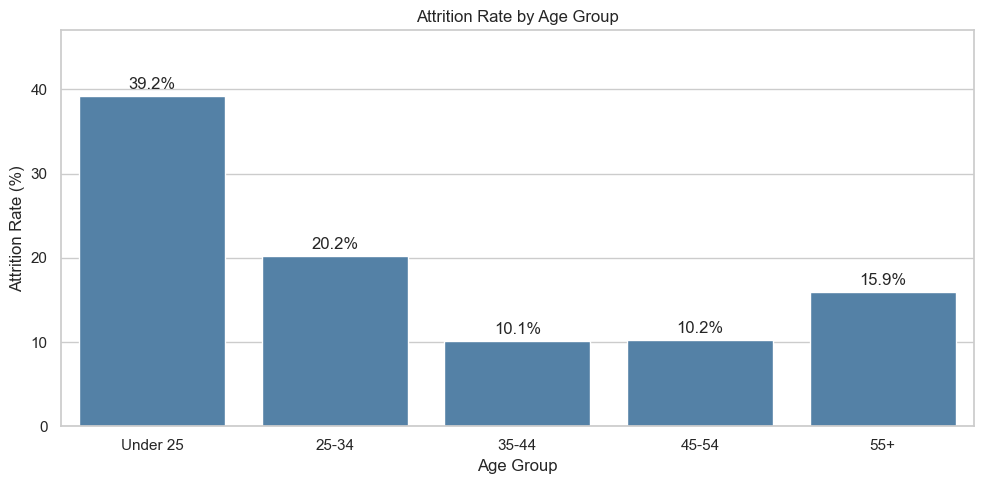

In [13]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=age_result,
    x="AgeGroup",
    y="attrition_rate",
    color="steelblue"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.title("Attrition Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Attrition Rate (%)")
plt.ylim(0, age_result["attrition_rate"].max() * 1.2)

plt.tight_layout()
plt.show()

### 4-3. 성별 및 결혼 여부에 따른 이직률 분석

성별과 결혼 여부에 따른 이직 현황을 비교한다.

각 집단의 직원 수와 이직률을 함께 확인하여 집단 규모의 차이로 인한 해석 오류를 방지한다.

이를 통해 인구통계학적 특성에 따라 이직률에 차이가 나타나는지 탐색한다.

In [15]:
gender_result = calculate_attrition_rate(
    hr_df,
    "Gender"
)

marital_result = calculate_attrition_rate(
    hr_df,
    "MaritalStatus"
)

print("성별 이직률")
display(gender_result)

print("결혼 여부별 이직률")
display(marital_result)

성별 이직률


,Gender,employee_count,attrition_count,attrition_rate
1,Male,882,150,17.006803
0,Female,588,87,14.795918


결혼 여부별 이직률


,MaritalStatus,employee_count,attrition_count,attrition_rate
2,Single,470,120,25.531915
1,Married,673,84,12.481426
0,Divorced,327,33,10.091743


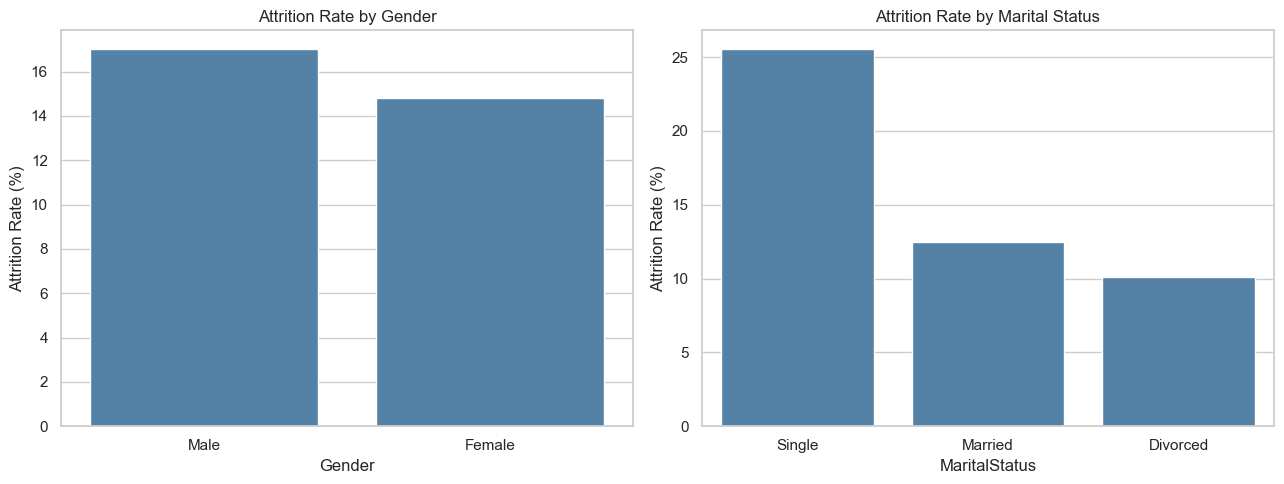

In [16]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

sns.barplot(
    data=gender_result,
    x="Gender",
    y="attrition_rate",
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Attrition Rate by Gender")
axes[0].set_ylabel("Attrition Rate (%)")

sns.barplot(
    data=marital_result,
    x="MaritalStatus",
    y="attrition_rate",
    color="steelblue",
    ax=axes[1]
)

axes[1].set_title("Attrition Rate by Marital Status")
axes[1].set_ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

### 4-4. 인구통계학적 특성 분석 결과

연령, 성별 및 결혼 여부에 따른 이직률을 비교한 결과를 정리한다.

#### 주요 분석 결과

- 연령대별: [이직률이 상대적으로 높은 연령대와 낮은 연령대]
- 성별: [성별에 따른 이직률 차이]
- 결혼 여부: [결혼 여부에 따른 이직률 차이]

#### 분석 인사이트

[실제 분석 결과를 바탕으로 주요 특징을 2~3개 작성]

#### 해석 시 유의사항

집단별 이직률 차이는 인구통계학적 특성과 이직 간의 연관성을 나타내는 결과이다.

연령이나 성별, 결혼 여부가 이직의 직접적인 원인이라고 단정할 수 없으며, 직무나 급여, 근무 환경 등 다른 변수의 영향도 함께 고려할 필요가 있다.